In [23]:
#| echo: false
from IPython.display import HTML, display
COMPACT_PRINT_CSS = "<style>\n@page { size: A4 portrait; margin: 11mm 12mm 12mm 12mm; }\n@media print {\n  :root { --jp-content-font-family: Arial, sans-serif; }\n  body { background: white !important; }\n  html, body { margin: 0 !important; padding: 0 !important; width: auto !important; }\n  body, .jp-RenderedHTMLCommon { font-family: Arial, sans-serif !important;\n    font-size: 9.6pt !important; line-height: 1.23 !important; color: #111 !important; }\n  .jp-Notebook { padding: 0 !important; margin: 0 !important; width: auto !important;\n    max-width: none !important; min-width: 0 !important; }\n  main, .jp-Cell, .jp-Cell-inputWrapper, .jp-Cell-outputWrapper,\n  .jp-InputArea, .jp-OutputArea, .jp-OutputArea-child, .jp-InputArea-editor,\n  .jp-RenderedHTMLCommon, .jp-RenderedText { min-width: 0 !important;\n    max-width: 100% !important; }\n  .jp-Cell { padding: 0 !important; margin: 0 0 4pt !important;\n    break-inside: auto !important; }\n  .jp-Cell-inputWrapper, .jp-Cell-outputWrapper { margin: 0 !important;\n    padding: 0 !important; }\n  .jp-InputPrompt, .jp-OutputPrompt, .jp-Collapser { display: none !important; }\n  .jp-RenderedMarkdown { padding: 0 !important; }\n  .jp-RenderedMarkdown h1 { font-size: 15pt !important; line-height: 1.14 !important;\n    margin: 0 0 6pt !important; break-after: avoid !important; }\n  .jp-RenderedMarkdown h2 { font-size: 12pt !important; line-height: 1.18 !important;\n    margin: 8pt 0 4pt !important; break-after: avoid !important; }\n  .jp-RenderedMarkdown p { margin: 3pt 0 5pt !important; orphans: 3; widows: 3; }\n  .jp-RenderedMarkdown a { color: #155d8b !important; text-decoration: none; }\n  .jp-InputArea-editor { border: 0.4pt solid #d7dce2 !important;\n    background: #f6f7f9 !important; border-radius: 0 !important; padding: 0 !important; }\n  .highlight { padding: 0 !important; margin: 0 !important; background: transparent !important; }\n  .highlight pre { font-family: 'DejaVu Sans Mono', Consolas, monospace !important;\n    font-size: 8.2pt !important; line-height: 1.17 !important; padding: 5pt 6pt !important;\n    margin: 0 !important; white-space: pre-wrap !important; overflow-wrap: anywhere !important;\n    word-break: normal !important; tab-size: 4; }\n  pre, code, .cm-editor, .jp-InputArea-editor { overflow: visible !important;\n    text-overflow: clip !important; max-height: none !important; }\n  .jp-RenderedText pre { font-family: 'DejaVu Sans Mono', Consolas, monospace !important;\n    font-size: 8.1pt !important; line-height: 1.2 !important; padding: 2pt 0 !important;\n    margin: 0 !important; white-space: pre-wrap !important; overflow-wrap: anywhere !important; }\n  .jp-RenderedImage { padding: 2pt 0 !important; text-align: center !important;\n    break-inside: avoid !important; }\n  .jp-RenderedImage img { display: block !important; width: 100% !important;\n    max-width: 100% !important; height: auto !important; margin: 0 auto !important;\n    break-inside: avoid !important; }\n  .jp-OutputArea-child { padding: 0 !important; break-inside: avoid !important; }\n .celltag_hide-input > .jp-Cell-inputWrapper { display: none !important; }\n  .anchor-link { display: none !important; }\n  mjx-container { font-size: 100% !important; }\n}\n</style>"
display(HTML(COMPACT_PRINT_CSS))

$\LARGE{EN3160\ Assignment\ 2}\\\LARGE{Fitting\ and\ Alignment}$

$\large{Index:\ 230544C}\\
\large{Name:\ Rathnayake\ M.\ A.\ G.\ K.\ N.}$

[GitHub folder](https://github.com/codingNR29/Image-processing/tree/5b7cef611a8a2a0e6ab166633ee592c571c799fe/Assignments/Assignment%201)

[GitHub repo](https://github.com/codingNR29/Image-processing.git)

In [ ]:
#Importing the libraries
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy import linalg


$Q1)$

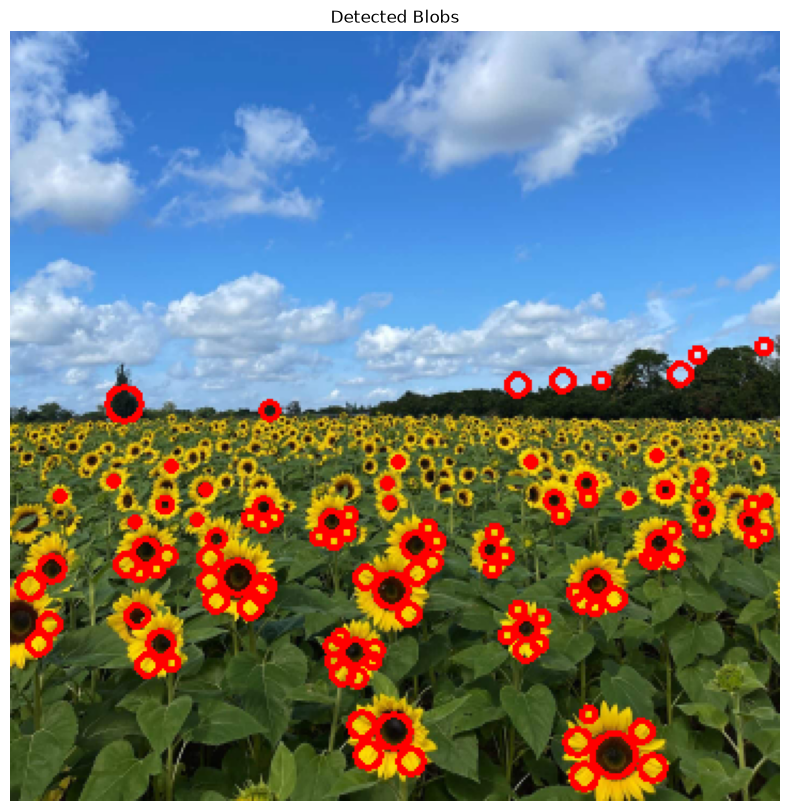

Largest detected circles:
Center (x, y) | Radius | Sigma
(282, 338) |  10.79 |   7.63
( 53, 174) |   8.63 |   6.10
(106, 255) |   8.63 |   6.10
(178, 261) |   8.63 |   6.10
(179, 327) |   8.63 |   6.10
(189, 240) |   6.91 |   4.88
( 63, 243) |   6.91 |   4.88
( 19, 251) |   6.91 |   4.88
(274, 258) |   6.91 |   4.88
(  9, 259) |   6.91 |   4.88

Sigma range: 1.60 to 36.38


In [4]:
#Importing the image
im_01 = cv.imread('the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_GRAYSCALE_4)

#Defining the number of scale levels
sigma_list = [1.6 * (1.25 ** i) for i in range(15)]

#Blank 3D space to store images
scale_space = np.zeros((im_01.shape[0], im_01.shape[1], len(sigma_list)), dtype=np.float64)

#Looping through the sigma values to store the image
for layer_index, sigma in enumerate(sigma_list):

    k = int(3*sigma)

    x = np.arange(-k, k + 1)
    y = np.arange(-k, k + 1)
    x, y = np.meshgrid(x, y) 

    g_xy = (1/(2*np.pi*sigma**2)) * np.exp(-(x**2 + y**2)/(2*sigma**2))

    #Laplacian of gaussian
    # first derivatives
    gx = np.gradient(g_xy, axis=1)
    gy = np.gradient(g_xy, axis=0)

    # second derivatives
    g_xx = np.gradient(gx, axis=1)
    g_yy = np.gradient(gy, axis=0)

    laplacian_of_gaussian = (sigma**2)*(g_xx + g_yy)

    #Applying the filter to the image
    im_laplace = cv.filter2D(im_01, cv.CV_64F, laplacian_of_gaussian)

    #Storing the image
    scale_space[:, :, layer_index] = im_laplace

#3D non maximum supression
def NMS_3D (image_block):

    #Blank image_block
    block = np.zeros((image_block.shape[0], image_block.shape[1], image_block.shape[2]), dtype=np.float64)

    #Getting the dimensions of the block
    rows, columns, height = np.shape(image_block)

    #Neighbours
    neighbours = [
                (-1, -1, -1), (-1, 0, -1), (-1, 1, -1),
                ( 0, -1, -1), ( 0, 0, -1), ( 0, 1, -1),
                ( 1, -1, -1), ( 1, 0, -1), ( 1, 1, -1) 
            ,
                  
                (-1, -1, 0), (-1, 0, 0), (-1, 1, 0),
                ( 0, -1, 0),             ( 0, 1, 0),
                ( 1, -1, 0), ( 1, 0, 0), ( 1, 1, 0) 
            , 
                  
                (-1, -1, 1), (-1, 0, 1), (-1, 1, 1),
                ( 0, -1, 1), ( 0, 0, 1), ( 0, 1, 1),
                ( 1, -1, 1), ( 1, 0, 1), ( 1, 1, 1) 
            ]


    #Squaring the image block to remove the negative values
    squared_image_block = np.multiply(image_block, image_block)

    #Adding a threshold to avoid unnesssary calculations
    threshold = 0.5 * squared_image_block.max()

    for i in range(1, rows - 1):
        for j in range(1, columns - 1):
            for k in range(1, height - 1):


                magnitude = squared_image_block[i, j, k]
                local_max_coordinates = [i, j, k]
                is_local_max = True

                #Ignoring the loop when when the value is too weak
                if magnitude < threshold :
                    continue

                for di, dj, dk in neighbours:

                    ni = i + di
                    nj = j + dj
                    nk = k + dk

                    if magnitude < squared_image_block[ni, nj, nk]:
                        is_local_max = False
                        break

                #If the center survives save the point
                if is_local_max:
                    block[i, j, k] = 255

    return block

#Image block after NMS 
scale_space_nms = NMS_3D(scale_space)

#Getting the indices of the non suppressed points
non_zero_values = np.argwhere(scale_space_nms > 0)

#Creating an image to draw colourd circles
im_with_blobs = cv.imread('the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)

#Itarting through the non zero points to draw circles
for point in non_zero_values:

    #Format , (row, column, scale_index)
    y = point[0]
    x = point[1]
    scale_index = point[2]

    sigma = sigma_list[scale_index]

    #Radius
    radius = int(sigma * np.sqrt(2))

    #Drawing the circle
    cv.circle(im_with_blobs, (x, y), radius, (0, 0, 255), 2)

# Plot the final masterpiece
plt.figure(figsize=(15, 10))
plt.imshow(cv.cvtColor(im_with_blobs, cv.COLOR_BGR2RGB))
plt.title("Detected Blobs")
plt.axis('off')
plt.show()

#Collect the parameters of the detected circles
detected_circles = []

for y, x, scale_index in non_zero_values:
    sigma = sigma_list[scale_index]
    radius = sigma * np.sqrt(2)

    detected_circles.append((x, y, radius, sigma))

#Sort circles by radius, largest first
detected_circles.sort(key=lambda circle: circle[2], reverse=True)

#Printing the values
print("Largest detected circles:")
print("Center (x, y) | Radius | Sigma")

for x, y, radius, sigma in detected_circles[:10]:
    print(f"({x:3d}, {y:3d}) | {radius:6.2f} | {sigma:6.2f}")

print(f"\nSigma range: {sigma_list[0]:.2f} to {sigma_list[-1]:.2f}")


$Q2)$

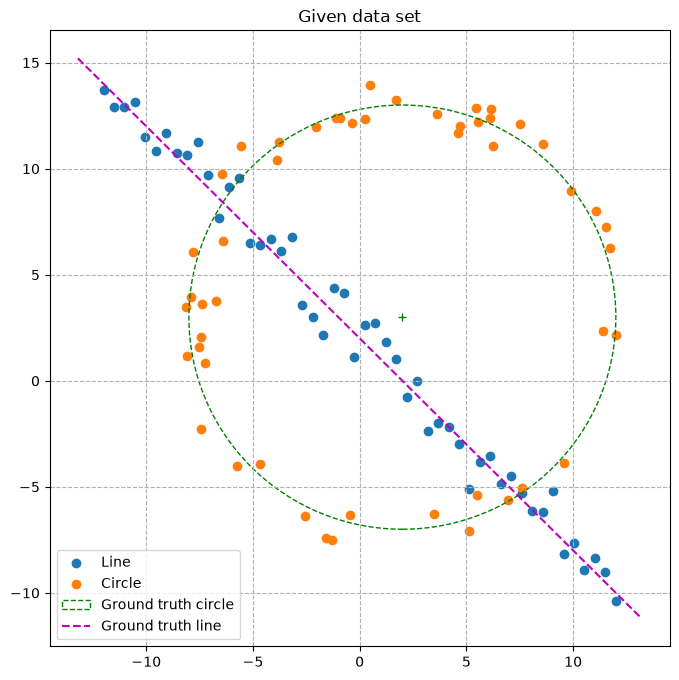

In [5]:
#Generating random data points
# np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3 # Center
s = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line)) # All points

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')

circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle', linestyle="--")
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g')
ax.set_title("Given data set")
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line', linestyle="--")
plt.legend()
plt.grid(linestyle="--")
plt.show()

$a)$

In [6]:
#RANSAC function
def RANSAC_fitting(X, y, threshold=1.0, N=100, min_consensus=30):

    #Combining x and y coordinates into points
    points = np.column_stack((X, y))

    #Variables for the best estimate
    max_number_of_inliers = 0
    best_parameters = None
    best_inliers = None
    best_sample = None

    #RANSAC iterations
    for i in range(N):

        #Randomly choosing two points
        idx1, idx2 = np.random.choice(len(points), 2, replace=False)

        p1 = points[idx1]
        p2 = points[idx2]

        # Direction vector
        dx = p2[0] - p1[0]
        dy = p2[1] - p1[1]

        norm = np.sqrt(dx**2 + dy**2)

        if norm < 1e-10:
            continue

        #Normalized line parameters
        a = -dy / norm
        b = dx / norm
        d = a * p1[0] + b * p1[1]

        #Perpendicular distances
        residuals = np.abs(a * points[:, 0] + b * points[:, 1] - d)

        #Finding inliers
        inliers = residuals < threshold
        number_of_inliers = np.sum(inliers)

        #Keeping the best model
        if number_of_inliers > max_number_of_inliers:
            max_number_of_inliers = number_of_inliers
            best_parameters = (a, b, d)
            best_inliers = inliers.copy()
            best_sample = points[[idx1, idx2]].copy()

    #Checking the minimum consensus
    if max_number_of_inliers < min_consensus:
        raise ValueError("Insufficient consensus. Adjust parameters.")

    #Refining the best line using Total Least Squares
    inlier_points = points[best_inliers]

    centroid = np.mean(inlier_points, axis=0)
    centered_points = inlier_points - centroid

    #The last right singular vector is the unit normal
    _, _, Vt = np.linalg.svd(centered_points)
    a, b = Vt[-1]

    d = a * centroid[0] + b * centroid[1]

    #Make d nonnegative
    if d < 0:
        a, b, d = -a, -b, -d

    refined_parameters = (a, b, d)

    #Recalculate inliers for the refined line
    residuals = np.abs(a * points[:, 0] + b * points[:, 1] - d)
    refined_inliers = residuals < threshold

    return refined_parameters, best_parameters, best_sample, refined_inliers


#Run RANSAC on the given point set 
best_line, sample_line, sample_points, line_inliers = RANSAC_fitting(X[:, 0], X[:, 1], threshold=1.0, N=100, min_consensus=30)

print("Ground truth: ", (0.7071, 0.7071, 1.4142))
print("RANSAC sample line:", sample_line)
print("Refined line:", best_line)
print("Number of line inliers:", np.sum(line_inliers))


Ground truth:  (0.7071, 0.7071, 1.4142)
RANSAC sample line: (np.float64(-0.7302245389362575), np.float64(-0.6832072326427248), np.float64(-1.3734035888427982))
Refined line: (np.float64(0.7106511832522114), np.float64(0.7035445229281739), np.float64(1.5026313367761035))
Number of line inliers: 47


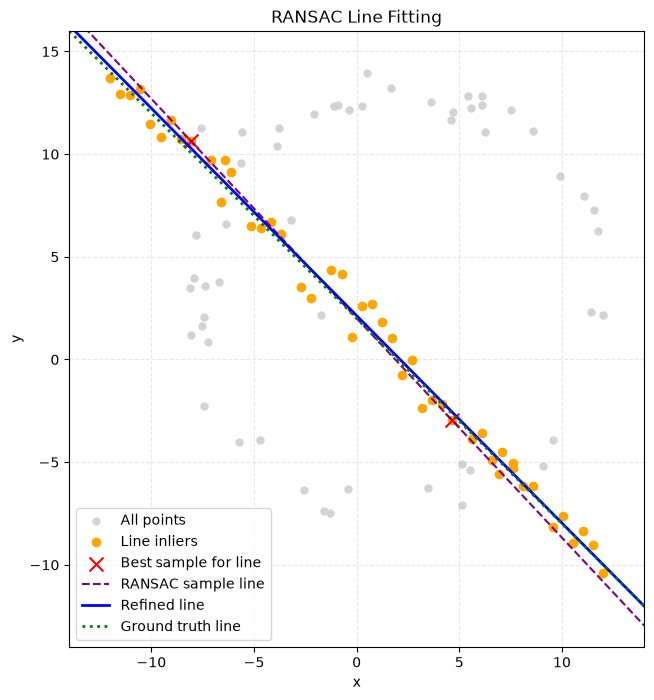

In [7]:
#Visualizing the line fit
fig, ax = plt.subplots(figsize=(8, 8))

#All points
ax.scatter(X[:, 0], X[:, 1], color='lightgray', s=25, label='All points')
           
#Line inliers
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], color='orange', s=35, label='Line inliers')
           
#Best sample points
ax.scatter(sample_points[:, 0], sample_points[:, 1], color='red', marker='x', s=100, label='Best sample for line')      

#X coordinates for the lines
x_range = np.linspace(-14, 14, 200)

#Line from the best RANSAC sample
a, b, d = sample_line
y_sample = (d - a * x_range) / b

ax.plot(x_range, y_sample, '--', color='purple', label='RANSAC sample line')
        
#Refined line
a, b, d = best_line
y_refined = (d - a * x_range) / b

ax.plot(x_range, y_refined, color='blue', linewidth=2, label='Refined line')
        
#Ground truth line
ax.plot(x_range, -x_range + 2, 'g:', linewidth=2, label='Ground truth line')

#Plot settings
ax.set_xlim(-14, 14)
ax.set_ylim(-14, 16)
ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('RANSAC Line Fitting')
ax.legend()
ax.grid(alpha=0.3, linestyle = "--")

plt.show()

$b)$

In [8]:
#Removing the line inliers
X_remaining = X[~line_inliers]

print("Original points:", len(X))
print("Remaining points:", len(X_remaining))


Original points: 100
Remaining points: 53


In [9]:
#Defining the RANSAC circle fitting
def RANSAC_circle(points, threshold=1.25, N=300, min_consensus=30):

    rng = np.random.default_rng(42)

    best_parameters = None
    best_inliers = None
    best_sample = None
    max_inliers = 0

    for i in range(N):

        #Randomly select three points
        indices = rng.choice(len(points), 3, replace=False)
        sample = points[indices]

        p1, p2, p3 = sample

        #Find the circle center using three points
        A = 2 * np.array([p2 - p1, p3 - p1])

        B = np.array([
            np.dot(p2, p2) - np.dot(p1, p1),
            np.dot(p3, p3) - np.dot(p1, p1)
        ])

        #Reject collinear or nearly collinear points
        if np.linalg.cond(A) > 1e8:
            continue

        center = np.linalg.solve(A, B)
        radius = np.linalg.norm(p1 - center)

        #Calculate radial errors
        distances = np.linalg.norm(points - center, axis=1)
        residuals = np.abs(distances - radius)

        #Find inliers
        inliers = residuals < threshold
        number_of_inliers = np.sum(inliers)

        if number_of_inliers > max_inliers:
            max_inliers = number_of_inliers
            best_parameters = (center[0], center[1], radius)
            best_inliers = inliers.copy()
            best_sample = sample.copy()

    if max_inliers < min_consensus:
        raise ValueError("Insufficient circle consensus.")

    #Refine using all inliers
    inlier_points = points[best_inliers]

    def circle_error(params):
        cx, cy, r = params
        distances = np.linalg.norm(
            inlier_points - np.array([cx, cy]), axis=1
        )
        return np.sum((distances - r)**2)

    result = minimize(
        circle_error,
        best_parameters,
        method="L-BFGS-B",
        bounds=[(None, None), (None, None), (1e-6, None)]
    )

    if not result.success:
        raise RuntimeError(result.message)

    refined_parameters = result.x

    #Find inliers of the refined circle
    cx, cy, r = refined_parameters
    distances = np.linalg.norm(
        points - np.array([cx, cy]), axis=1
    )
    refined_inliers = np.abs(distances - r) < threshold

    return refined_parameters, best_parameters, best_sample, refined_inliers

#Run RANSAC circle fitting
best_circle, sample_circle, circle_sample_points, circle_inliers = RANSAC_circle(X_remaining, threshold=1.25, N=300,   min_consensus=30)

print("Ground truth circle: (2, 3, 10)")
print("RANSAC sample circle:", sample_circle)
print("Refined circle:", best_circle)
print("Number of circle inliers:", np.sum(circle_inliers))


Ground truth circle: (2, 3, 10)
RANSAC sample circle: (np.float64(1.613865719761574), np.float64(2.94997856410045), np.float64(9.811884494734757))
Refined circle: [ 2.05067045  2.95781954 10.01218184]
Number of circle inliers: 49


$c)$

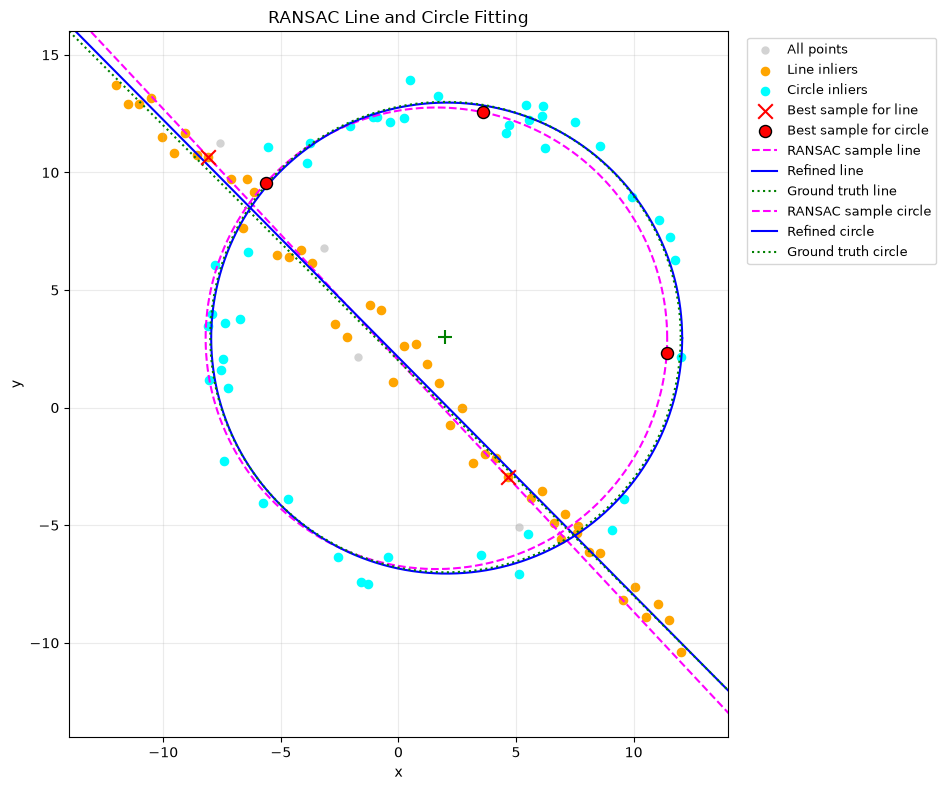

In [10]:
#Full RANSAC Visualization
fig, ax = plt.subplots(figsize=(10, 8))

#All points
ax.scatter(X[:, 0], X[:, 1], color='lightgray', s=25, label='All points')
           
# Line inliers
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], color='orange', s=35, label='Line inliers')

# Circle inliers
circle_points = X_remaining[circle_inliers]
ax.scatter(circle_points[:, 0], circle_points[:, 1], color='cyan', s=35, label='Circle inliers')

# Best line sample (2 points)
ax.scatter(sample_points[:, 0], sample_points[:, 1], color='red', marker='x', s=110, label='Best sample for line', zorder=5)

# Best circle sample (3 points)
ax.scatter(circle_sample_points[:, 0], circle_sample_points[:, 1], color='red', marker='o', s=75, edgecolors='black', label='Best sample for circle', zorder=6)

#Draw lines in normal form: ax + by = d
def draw_line(ax, parameters, style, color, label):
    a, b, d = parameters
    t = np.linspace(-22, 22, 300)
    x = a*d - b*t
    y = b*d + a*t
    ax.plot(x, y, style, color=color, label=label)

#Line from the RANSAC sample
draw_line(ax, sample_line, '--', 'magenta', 'RANSAC sample line')

#Refined line
draw_line(ax, best_line, '-', 'blue', 'Refined line')

#Ground truth line: y = -x + 2
x_gt = np.linspace(-14, 14, 300)
ax.plot(x_gt, -x_gt + 2, 'g:', label='Ground truth line')

#Function to draw circles
theta = np.linspace(0, 2*np.pi, 400)

def draw_circle(ax, parameters, style, color, label):
    cx, cy, r = parameters

    x = cx + r * np.cos(theta)
    y = cy + r * np.sin(theta)

    ax.plot(x, y, style, color=color, label=label)

#Circle estimated from the best RANSAC sample
draw_circle(ax, sample_circle, '--', 'magenta', 'RANSAC sample circle')

#Refined circle
draw_circle(ax, best_circle, '-', 'blue', 'Refined circle')

#Ground truth circle
draw_circle(ax, (2, 3, 10), ':', 'green', 'Ground truth circle')

#Ground truth center
ax.scatter(2, 3, marker='+', color='green', s=100)

#Formatting
ax.set_xlim(-14, 14)
ax.set_ylim(-14, 16)
ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('RANSAC Line and Circle Fitting')

ax.grid(alpha=0.25)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
          
plt.tight_layout()
plt.show()

$d)$

In [11]:
#Fitting the circle first using all points
circle_first, circle_sample_first, circle_pts_first, circle_mask_first = RANSAC_circle(X, threshold=1.25, N=300, min_consensus=30)

print("Circle-first parameters:", circle_first)
print("Circle inliers:", np.sum(circle_mask_first))


#Remove circle inliers
X_after_circle = X[~circle_mask_first]

#Fit line to remaining points
np.random.seed(42)

line_second, line_sample_second, line_pts_second, line_mask_second = RANSAC_fitting(X_after_circle[:, 0], X_after_circle[:, 1], threshold=1.0, N=100, min_consensus=30)

print("Line-second parameters:", line_second)
print("Line inliers:", np.sum(line_mask_second))

#Comparing procedures
print("Line First")
print("Line:", np.round(best_line, 4))
print("Circle:", np.round(best_circle, 4))

print("\nCircle First")
print("Line:", np.round(line_second, 4))
print("Circle:", np.round(circle_first, 4))

print("\nGround Truth")
print("Line:", (0.7071, 0.7071, 1.4142))
print("Circle:", (2, 3, 10))


Circle-first parameters: [ 2.08664662  2.94115094 10.0311007 ]
Circle inliers: 59
Line-second parameters: (np.float64(0.7101095472821876), np.float64(0.7040912091900355), np.float64(1.5070720903628607))
Line inliers: 37
Line First
Line: [0.7107 0.7035 1.5026]
Circle: [ 2.0507  2.9578 10.0122]

Circle First
Line: [0.7101 0.7041 1.5071]
Circle: [ 2.0866  2.9412 10.0311]

Ground Truth
Line: (0.7071, 0.7071, 1.4142)
Circle: (2, 3, 10)


$Q3)$

Homography matrix:
[[ 2.95782411e-01 -1.72997100e-02  1.47455994e+02]
 [ 9.93856559e-02  3.09474641e-01  2.06848007e+02]
 [ 1.93805059e-04 -3.31910562e-05  1.00000000e+00]]


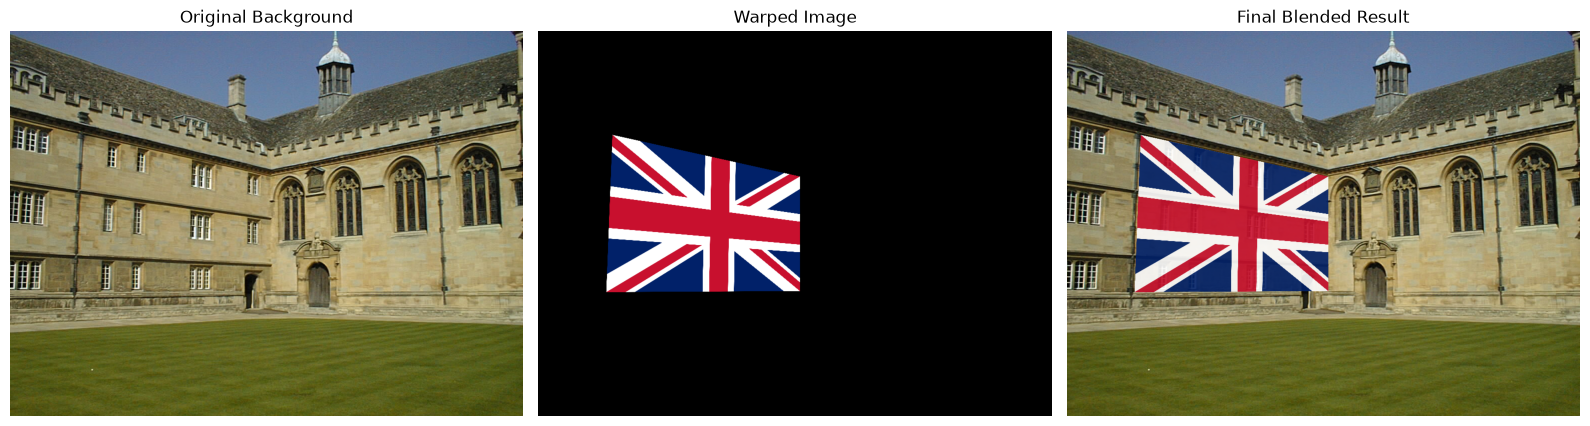

Second homography matrix:
[[ 3.40267313e-02 -2.68489436e-18  8.00000000e+01]
 [-2.19849865e-02  6.67129951e-02  2.61000000e+02]
 [-7.04195597e-05 -7.98526191e-20  1.00000000e+00]]


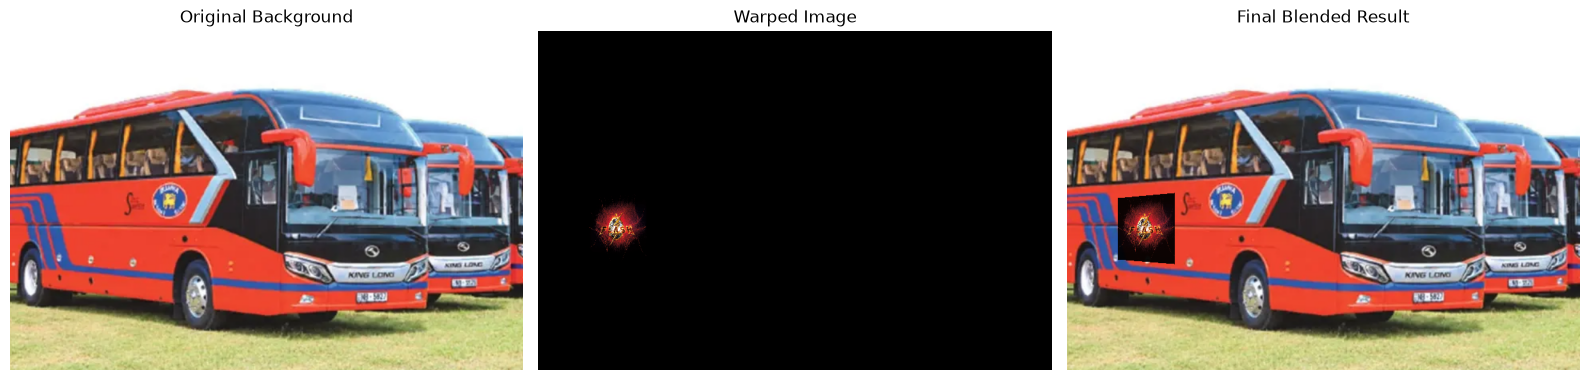

In [24]:
#Point selecting function
def select_four_points(image):

    #Resize image for easier selection
    height, width = image.shape[:2]
    scale = min(1.0, 1000 / max(height, width))

    display = cv.resize(image, None, fx=scale, fy=scale)
    points = []

    window_name = "Select 4 Points"

    def mouse_callback(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
            points.append((x, y))

    cv.namedWindow(window_name, cv.WINDOW_NORMAL)
    cv.setMouseCallback(window_name, mouse_callback)

    while True:
        canvas = display.copy()

        #Draw selected points
        for i, (x, y) in enumerate(points):
            cv.circle(canvas, (x, y), 5, (0, 0, 255), -1)
            cv.putText(canvas, str(i + 1), (x + 8, y - 8),
                       cv.FONT_HERSHEY_SIMPLEX, 0.7,
                       (0, 0, 255), 2)

        #Draw boundary after four points are chosen
        if len(points) == 4:
            polygon = np.array(points, dtype=np.int32)
            cv.polylines(canvas, [polygon], True,
                         (0, 255, 0), 2)

        cv.imshow(window_name, canvas)

        key = cv.waitKey(20) & 0xFF

        #Press R to restart selection
        if key == ord('r'):
            points.clear()

        #Press Enter to confirm
        elif key in (13, 10) and len(points) == 4:
            break

        #Press ESC to cancel
        elif key == 27:
            cv.destroyWindow(window_name)
            raise ValueError("Point selection cancelled")

    cv.destroyWindow(window_name)

    #Convert back to original image coordinates
    return np.array(points, dtype=np.float32) / scale

#Calculating homography and warping the image
def apply_homography(background, source, destination_points,
                     alpha=0.9):

    #Source image dimensions
    h_src, w_src = source.shape[:2]

    #Background image dimensions
    h_bg, w_bg = background.shape[:2]

    #Four corners of the source image
    source_points = np.float32([
        [0, 0],
        [w_src - 1, 0],
        [w_src - 1, h_src - 1],
        [0, h_src - 1]
    ])

    #Calculate homography matrix
    H = cv.getPerspectiveTransform(
        source_points, destination_points
    )

    #Warp the source image
    warped = cv.warpPerspective(
        source, H, (w_bg, h_bg)
    )

    #Create a mask for the source image
    mask = np.ones((h_src, w_src), dtype=np.uint8) * 255

    #Warp the mask
    warped_mask = cv.warpPerspective(
        mask, H, (w_bg, h_bg)
    )

    #Normalize mask and apply transparency
    blend_mask = (warped_mask.astype(np.float32) / 255.0)
    blend_mask = (alpha * blend_mask)[:, :, None]

    #Alpha blending
    result = (
        blend_mask * warped.astype(np.float32)
        + (1 - blend_mask) * background.astype(np.float32)
    )

    result = np.clip(result, 0, 255).astype(np.uint8)

    return H, warped, result

#Read images
background = cv.imread("wadham.jpg")
source = cv.imread("flag.png")

if background is None or source is None:
    raise FileNotFoundError("Check the image filenames and paths.")

#Select four points on the building
destination_points = select_four_points(background)

#Apply the homography
H, warped, result = apply_homography(
    background, source, destination_points, alpha=0.9
)

print("Homography matrix:")
print(H)

#Show results
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

images = [background, warped, result]
titles = ["Original Background", "Warped Image", "Final Blended Result"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

#Second image pair
background_2 = cv.imread("buses.png")
source_2 = cv.imread("flash.jpg")

if background_2 is None or source_2 is None:
    raise FileNotFoundError("Check the second image pair.")

destination_points_2 = select_four_points(background_2)

H2, warped_2, result_2 = apply_homography(
    background_2,
    source_2,
    destination_points_2,
    alpha=0.95
)

print("Second homography matrix:")
print(H2)

#Show results
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

images = [background_2, warped_2, result_2]
titles = ["Original Background", "Warped Image", "Final Blended Result"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()